<a href="https://colab.research.google.com/github/em2tech/Machine_Learning_SJU/blob/main/HW7/Wine_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**HW7 - Unsupervised Learning on the Wine Recognition Dataset**

K-Means, DBSCAN and HDBSCAN

The Wine Recognition dataset contains 178 Italian wines from three grape cultivars, each described by 13 chemical measurements such as alcohol, flavanoids and proline. This assignment hides the class labels and asks whether K-Means, DBSCAN and HDBSCAN can rediscover the three cultivars from the chemistry alone. The true labels are never used to fit the clustering models. They are used only afterward to evaluate the results, through the Adjusted Rand Index, cross-tabulations and the Task 8 classification experiment.

**Setup: Imports, Style and Reproducibility**

This cell imports every library the later tasks need. NumPy and pandas handle the data, Matplotlib and Seaborn draw the plots, and SciPy provides hierarchical clustering. From scikit-learn it imports the dataset loader (load_wine), StandardScaler, KMeans, DBSCAN, HDBSCAN and PCA, plus tools for evaluation and for the Task 8 classifier. HDBSCAN is built into scikit-learn since version 1.3, so nothing extra needs to be installed on Colab. A global RANDOM_STATE = 42 is passed to every model that involves randomness, so re-running the notebook gives the same results. A fixed colorblind-safe palette and a distinct marker shape keep each cluster consistent across all figures, and noise points always appear as gray x markers.


In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import seaborn as sns

import sklearn
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, accuracy_score, confusion_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- consistent visual identity across all figures ----
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
CLUSTER_MARKERS = ["o", "s", "^", "D", "v", "P", "*", "h"]
NOISE_COLOR = "#9a9993"
INK, INK2 = "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlesize": 12,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "legend.frameon": False, "font.size": 10,
})

_orig_heatmap = sns.heatmap
def _heatmap_nogrid(*a, **k):
    ax = _orig_heatmap(*a, **k); ax.grid(False); return ax
sns.heatmap = _heatmap_nogrid

def scatter_clusters(ax, X2, labels, title, centers=None):
    # Draw a 2D scatter of cluster labels; label -1 is treated as noise.
    labels = np.asarray(labels)
    for c in sorted(set(labels)):
        m = labels == c
        if c == -1:
            ax.scatter(X2[m, 0], X2[m, 1], c=NOISE_COLOR, marker="x", s=36, linewidths=1.4,
                       label=f"Noise (n={m.sum()})", zorder=2)
        else:
            ax.scatter(X2[m, 0], X2[m, 1], c=CLUSTER_COLORS[c % 8], marker=CLUSTER_MARKERS[c % 8],
                       s=40, edgecolors="white", linewidths=0.8, label=f"Cluster {c} (n={m.sum()})", zorder=3)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=220, c=INK, edgecolors="white",
                   linewidths=1.5, label="Centroid", zorder=4)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(title)
    ax.legend(loc="best", fontsize=8)

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


**Task 1: Exploratory Data Analysis and Feature Standardization**

What this code cell does
This cell loads the dataset with load_wine(), puts the 13 chemical features in a labelled DataFrame, and stores the cultivar labels separately so no clustering model ever sees them. It prints the data's size (178 wines × 13 features) and the class counts (59 / 71 / 48). It then prints summary statistics for every feature, which reveal a huge difference in scale: proline runs into the hundreds and thousands, while hue stays below 2. A missing-value check confirms the data is complete. All 13 features are then standardized with StandardScaler, using z = (x − μ) / σ, so each has mean 0 and standard deviation 1 and gets an equal say in distance calculations. Three figures show the effect. Side-by-side box plots show proline dominating the raw data and all features comparable after scaling. A variance chart on a log scale shows how far one feature would have dominated. Before-and-after histograms show that scaling changes the units of each feature but not the shape of its distribution.
Why it matters
Clustering depends entirely on distances. Without scaling, the clusters would mostly reflect proline alone, the feature with the largest numbers, rather than the full chemical profile.


DATASET DIMENSIONS
Samples  : 178
Features : 13
Shape    : (178, 13)

Ground-truth cultivar counts (used ONLY for evaluation):
Class 0    59
Class 1    71
Class 2    48

FEATURE SUMMARY STATISTICS (raw units)
                              count     mean      std     min      25%      50%      75%      max    range
alcohol                       178.0   13.001    0.812   11.03   12.362   13.050   13.678    14.83     3.80
malic_acid                    178.0    2.336    1.117    0.74    1.602    1.865    3.082     5.80     5.06
ash                           178.0    2.367    0.274    1.36    2.210    2.360    2.558     3.23     1.87
alcalinity_of_ash             178.0   19.495    3.340   10.60   17.200   19.500   21.500    30.00    19.40
magnesium                     178.0   99.742   14.282   70.00   88.000   98.000  107.000   162.00    92.00
total_phenols                 178.0    2.295    0.626    0.98    1.742    2.355    2.800     3.88     2.90
flavanoids                    178.0    2.0

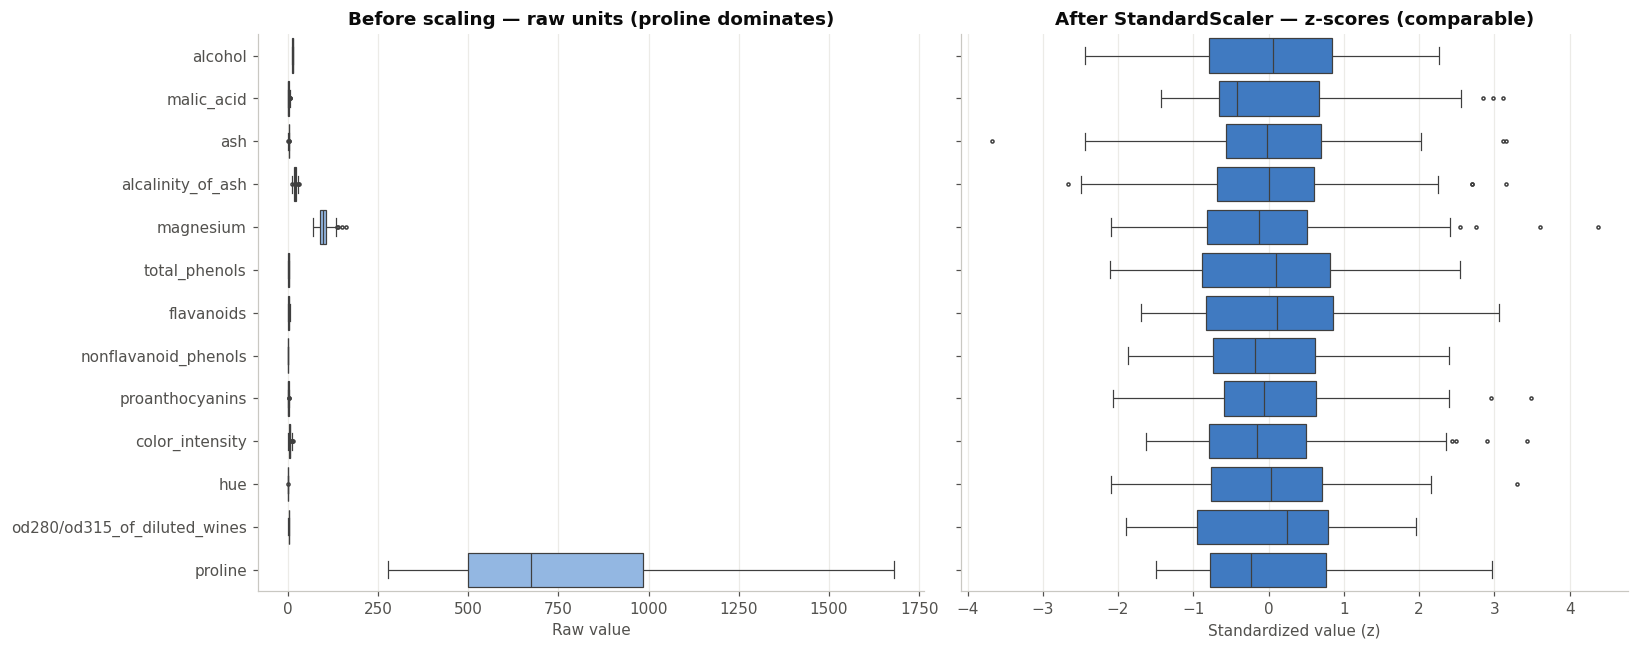

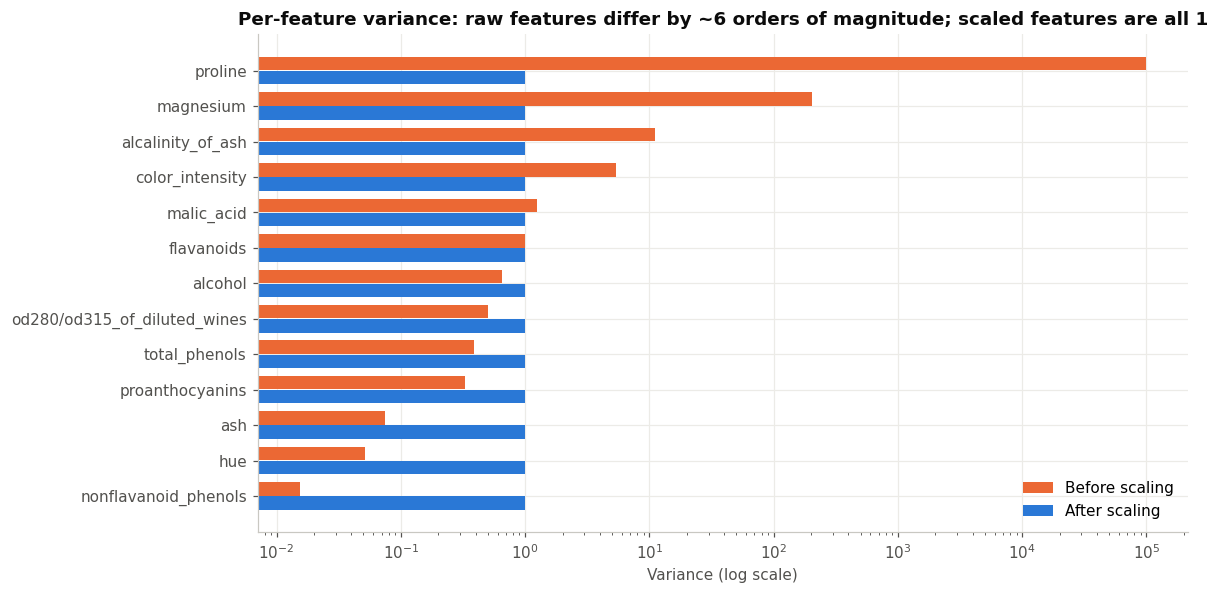

Share of total raw variance contributed by each feature (top 4):
proline              99.774 %
magnesium             0.205 %
alcalinity_of_ash     0.011 %
color_intensity       0.005 %


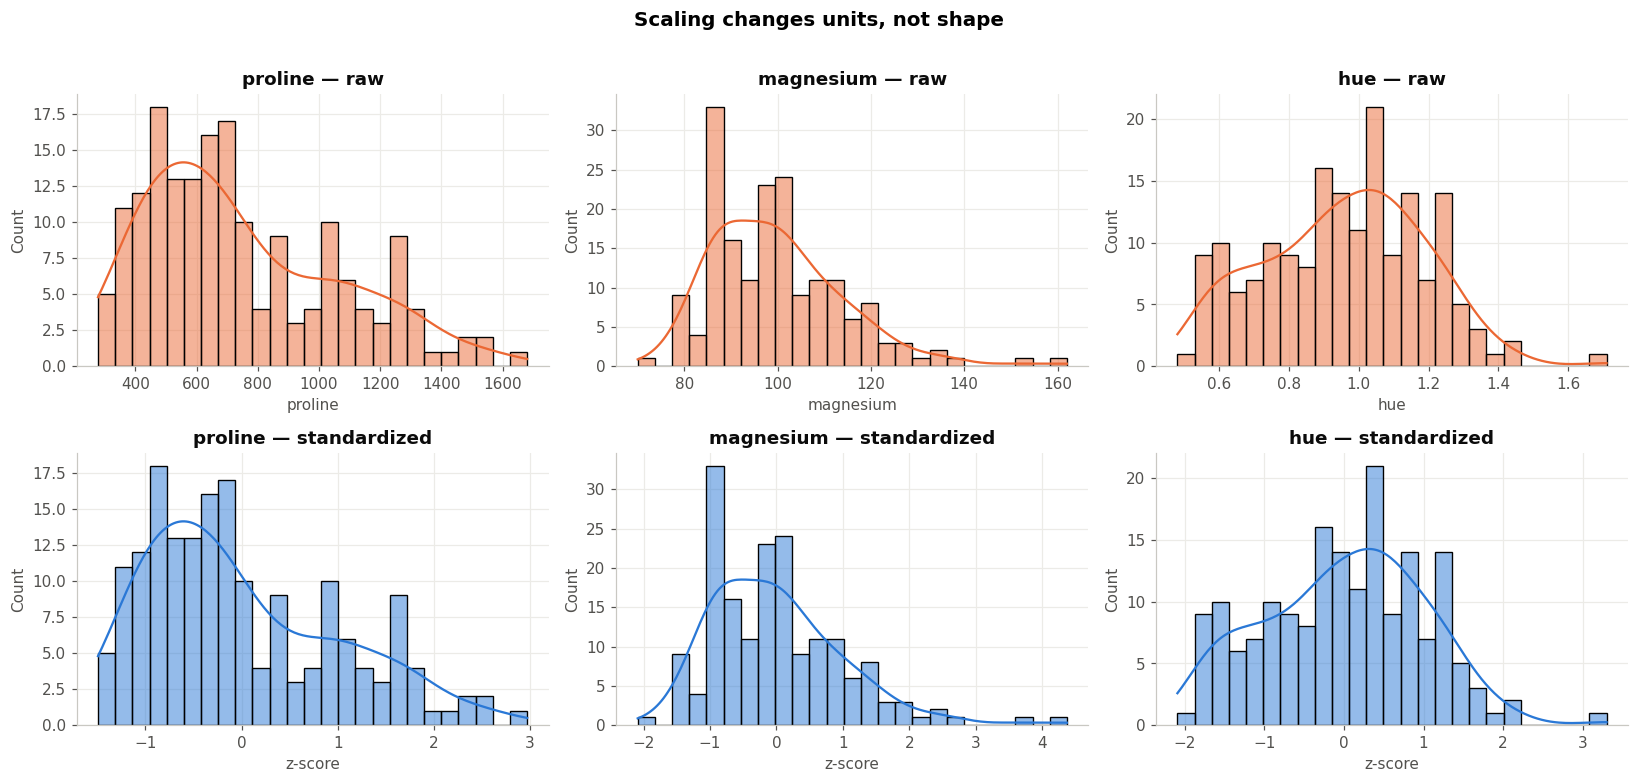

In [2]:
wine = load_wine()
X_raw = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target
class_names = [f"Class {i}" for i in range(3)]

print("=" * 70)
print("DATASET DIMENSIONS")
print("=" * 70)
print(f"Samples  : {X_raw.shape[0]}")
print(f"Features : {X_raw.shape[1]}")
print(f"Shape    : {X_raw.shape}")
print("\nGround-truth cultivar counts (used ONLY for evaluation):")
print(pd.Series(y).value_counts().sort_index().rename(lambda i: f"Class {i}").to_string())

print("\n" + "=" * 70)
print("FEATURE SUMMARY STATISTICS (raw units)")
print("=" * 70)
summary = X_raw.describe().T
summary["range"] = summary["max"] - summary["min"]
pd.set_option("display.width", 140)
print(summary.round(3).to_string())

print("\n" + "=" * 70)
print("MISSING VALUE CHECK")
print("=" * 70)
missing = X_raw.isnull().sum()
print(missing.to_string())
print(f"\nTotal missing values: {missing.sum()}  ->  "
      f"{'dataset is complete' if missing.sum() == 0 else 'imputation required'}")
print(f"Duplicate rows      : {X_raw.duplicated().sum()}")

# ---------------- Standardization ----------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_scaled_df = pd.DataFrame(X_scaled, columns=wine.feature_names)

print("\n" + "=" * 70)
print("AFTER STANDARDIZATION (mean should be 0, std should be 1)")
print("=" * 70)
print(pd.DataFrame({"mean": X_scaled_df.mean().round(6), "std": X_scaled_df.std(ddof=0).round(6)}).to_string())

# ---------------- Figure 1: box plots before / after ----------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.boxplot(data=X_raw, orient="h", ax=axes[0], color="#86b6ef", fliersize=2, linewidth=0.8)
axes[0].set_title("Before scaling — raw units (proline dominates)")
axes[0].set_xlabel("Raw value")
sns.boxplot(data=X_scaled_df, orient="h", ax=axes[1], color="#2a78d6", fliersize=2, linewidth=0.8)
axes[1].set_title("After StandardScaler — z-scores (comparable)")
axes[1].set_xlabel("Standardized value (z)")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

# ---------------- Figure 2: variance before / after ----------------
var_df = pd.DataFrame({"Before scaling": X_raw.var(ddof=0), "After scaling": X_scaled_df.var(ddof=0)})
var_df = var_df.sort_values("Before scaling")
fig, ax = plt.subplots(figsize=(11, 5.5))
yy = np.arange(len(var_df))
ax.barh(yy + 0.2, var_df["Before scaling"], height=0.38, color="#eb6834", label="Before scaling")
ax.barh(yy - 0.2, var_df["After scaling"], height=0.38, color="#2a78d6", label="After scaling")
ax.set_yticks(yy); ax.set_yticklabels(var_df.index)
ax.set_xscale("log"); ax.set_xlabel("Variance (log scale)")
ax.set_title("Per-feature variance: raw features differ by ~6 orders of magnitude; scaled features are all 1")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

share = (X_raw.var(ddof=0) / X_raw.var(ddof=0).sum()).sort_values(ascending=False)
print("Share of total raw variance contributed by each feature (top 4):")
print((share.head(4) * 100).round(3).astype(str).add(" %").to_string())

# ---------------- Figure 3: distribution shapes preserved ----------------
feats = ["proline", "magnesium", "hue"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, f in enumerate(feats):
    sns.histplot(X_raw[f], bins=25, kde=True, ax=axes[0, j], color="#eb6834")
    axes[0, j].set_title(f"{f} — raw"); axes[0, j].set_xlabel(f)
    sns.histplot(X_scaled_df[f], bins=25, kde=True, ax=axes[1, j], color="#2a78d6")
    axes[1, j].set_title(f"{f} — standardized"); axes[1, j].set_xlabel("z-score")
plt.suptitle("Scaling changes units, not shape", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Task 2: Choosing k with the Elbow Method and Silhouette Analysis**

What this code cell does:
K-Means needs the number of clusters, k, chosen in advance. Since the labels are hidden, this cell estimates k from the data by fitting K-Means for every k from 1 to 10, keeping the best of 10 restarts each time. It then computes two diagnostics. The first is the Elbow Method, which tracks inertia: the total squared distance from each wine to its cluster centre. Inertia always falls as k grows, so the goal is the "elbow" where adding another cluster stops helping much. To avoid eyeballing it, the code picks the point farthest from a straight line drawn between the curve's first and last points. The second is the silhouette score, computed for k = 2 to 10, which compares how close each wine is to its own cluster with how close it is to the nearest other cluster. It ranges from −1 to +1, and the k with the highest average score is chosen.
Output
The cell shows the elbow and silhouette curves side by side, each with its suggested k highlighted, and prints a table of inertia, inertia drop and silhouette score for each k. It also prints the k each method recommends and whether it matches the true number of cultivars (3). As a final check, it reports the Adjusted Rand Index (ARI) of the k = 3 solution against the true labels, where 1 means perfect agreement and about 0 means random.


 k  inertia  drop_to_next_%  silhouette
 1   2314.0            28.3         NaN
 2   1658.8            23.0      0.2593
 3   1277.9             8.0      0.2849
 4   1175.4             5.6      0.2602
 5   1109.5             5.7      0.2016
 6   1046.0             6.2      0.2372
 7    981.6             4.7      0.2036
 8    935.2             4.8      0.1570
 9    889.9             4.9      0.1499
10    845.9             NaN      0.1436


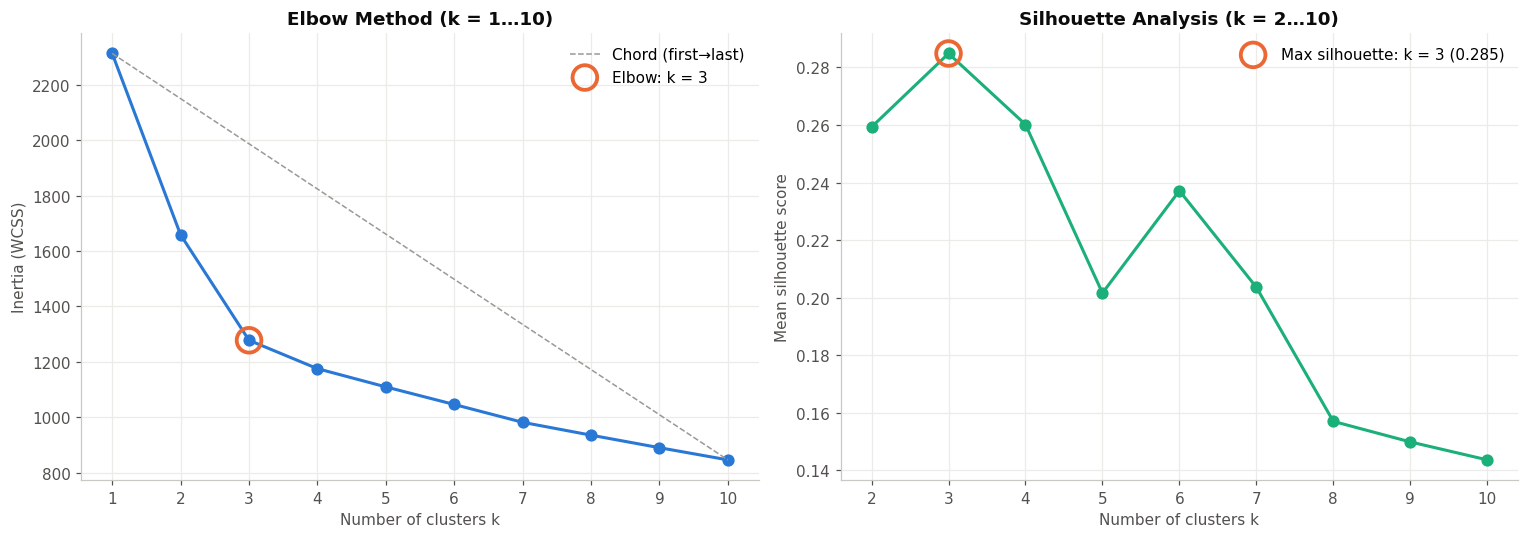


Optimal k suggested by the Elbow Method      : 3
Optimal k suggested by the Silhouette Score  : 3
True number of wine cultivars                : 3
Both metrics agree with ground truth?        : True
ARI of K-Means (k=3) vs. true cultivars      : 0.8975

Cross-tabulation K-Means (k=3, 13-D) vs. true cultivar:
True class        0   1   2
K-Means cluster            
0                 0  65   0
1                 0   3  48
2                59   3   0


In [3]:
K_RANGE = range(1, 11)
inertias, sil_scores = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    if k >= 2:
        sil_scores[k] = silhouette_score(X_scaled, km.labels_)

# ---- objective elbow: point with max perpendicular distance to the chord ----
ks = np.array(list(K_RANGE), dtype=float)
inn = np.array(inertias)
kn = (ks - ks.min()) / (ks.max() - ks.min())
ivn = (inn - inn.min()) / (inn.max() - inn.min())
p1, p2 = np.array([kn[0], ivn[0]]), np.array([kn[-1], ivn[-1]])
v = p2 - p1; w = np.c_[kn, ivn] - p1
dist_to_chord = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)
k_elbow = int(ks[np.argmax(dist_to_chord)])
k_sil = max(sil_scores, key=sil_scores.get)

table = pd.DataFrame({
    "k": list(K_RANGE),
    "inertia": np.round(inertias, 1),
    "drop_to_next_%": [round(100 * (inertias[i] - inertias[i + 1]) / inertias[i], 1) if i < 9 else np.nan for i in range(10)],
    "silhouette": [round(sil_scores.get(k, np.nan), 4) for k in K_RANGE],
})
print(table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_RANGE), inertias, "-o", color="#2a78d6", lw=2, ms=7)
axes[0].plot([1, 10], [inertias[0], inertias[-1]], "--", color=NOISE_COLOR, lw=1, label="Chord (first→last)")
axes[0].scatter([k_elbow], [inertias[k_elbow - 1]], s=260, facecolors="none", edgecolors="#eb6834", lw=2.5,
                zorder=5, label=f"Elbow: k = {k_elbow}")
axes[0].set_xticks(list(K_RANGE)); axes[0].set_xlabel("Number of clusters k"); axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Elbow Method (k = 1…10)"); axes[0].legend()

sk = list(sil_scores.keys()); sv = list(sil_scores.values())
axes[1].plot(sk, sv, "-o", color="#1baf7a", lw=2, ms=7)
axes[1].scatter([k_sil], [sil_scores[k_sil]], s=260, facecolors="none", edgecolors="#eb6834", lw=2.5,
                zorder=5, label=f"Max silhouette: k = {k_sil} ({sil_scores[k_sil]:.3f})")
axes[1].set_xticks(sk); axes[1].set_xlabel("Number of clusters k"); axes[1].set_ylabel("Mean silhouette score")
axes[1].set_title("Silhouette Analysis (k = 2…10)"); axes[1].legend()
plt.tight_layout(); plt.show()

kmeans_13d = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
km_labels = kmeans_13d.labels_
print("\n" + "=" * 70)
print(f"Optimal k suggested by the Elbow Method      : {k_elbow}")
print(f"Optimal k suggested by the Silhouette Score  : {k_sil}")
print(f"True number of wine cultivars                : 3")
print(f"Both metrics agree with ground truth?        : {k_elbow == 3 and k_sil == 3}")
print(f"ARI of K-Means (k=3) vs. true cultivars      : {adjusted_rand_score(y, km_labels):.4f}")
print("=" * 70)
print("\nCross-tabulation K-Means (k=3, 13-D) vs. true cultivar:")
print(pd.crosstab(pd.Series(km_labels, name="K-Means cluster"), pd.Series(y, name="True class")))

**Task 3: PCA to 2D and Voronoi Decision Boundaries for K-Means (k = 3)**

What this code cell does:
First, the cell uses PCA to project the 13 standardized features onto two principal components, purely so the data can be plotted. Tasks 4 to 8 still use the full 13 features. It prints how much of the variance the two components keep (about 55%) and which chemicals drive each axis. PCA is run on the scaled data because on raw data the first component would be almost entirely proline. Next, a K-Means model with k = 3 is fit on the two PCA coordinates so its boundaries can be drawn exactly. Since K-Means assigns every point to its nearest centroid, its decision regions form a Voronoi diagram: each centroid owns the area closer to it than to any other, and the borders are straight lines. The code colours these regions by predicting the cluster for every point on a fine grid. It draws the borders and checks them against Voronoi lines computed directly from the centroids with SciPy. Finally, it plots the wines by cluster, with the centroids marked as black X markers.
A second panel shows the same 2D plot coloured by true cultivar, so the K-Means regions can be compared with the real classes. The cell also prints the 2D model's ARI and a cross-tabulation of its clusters against the true classes.


Explained variance ratio: PC1 = 36.199%, PC2 = 19.207%, total = 55.406%
Top loadings PC1: flavanoids (+0.42), total_phenols (+0.39), od280/od315_of_diluted_wines (+0.38), proanthocyanins (+0.31)
Top loadings PC2: color_intensity (+0.53), alcohol (+0.48), proline (+0.36), ash (+0.32)


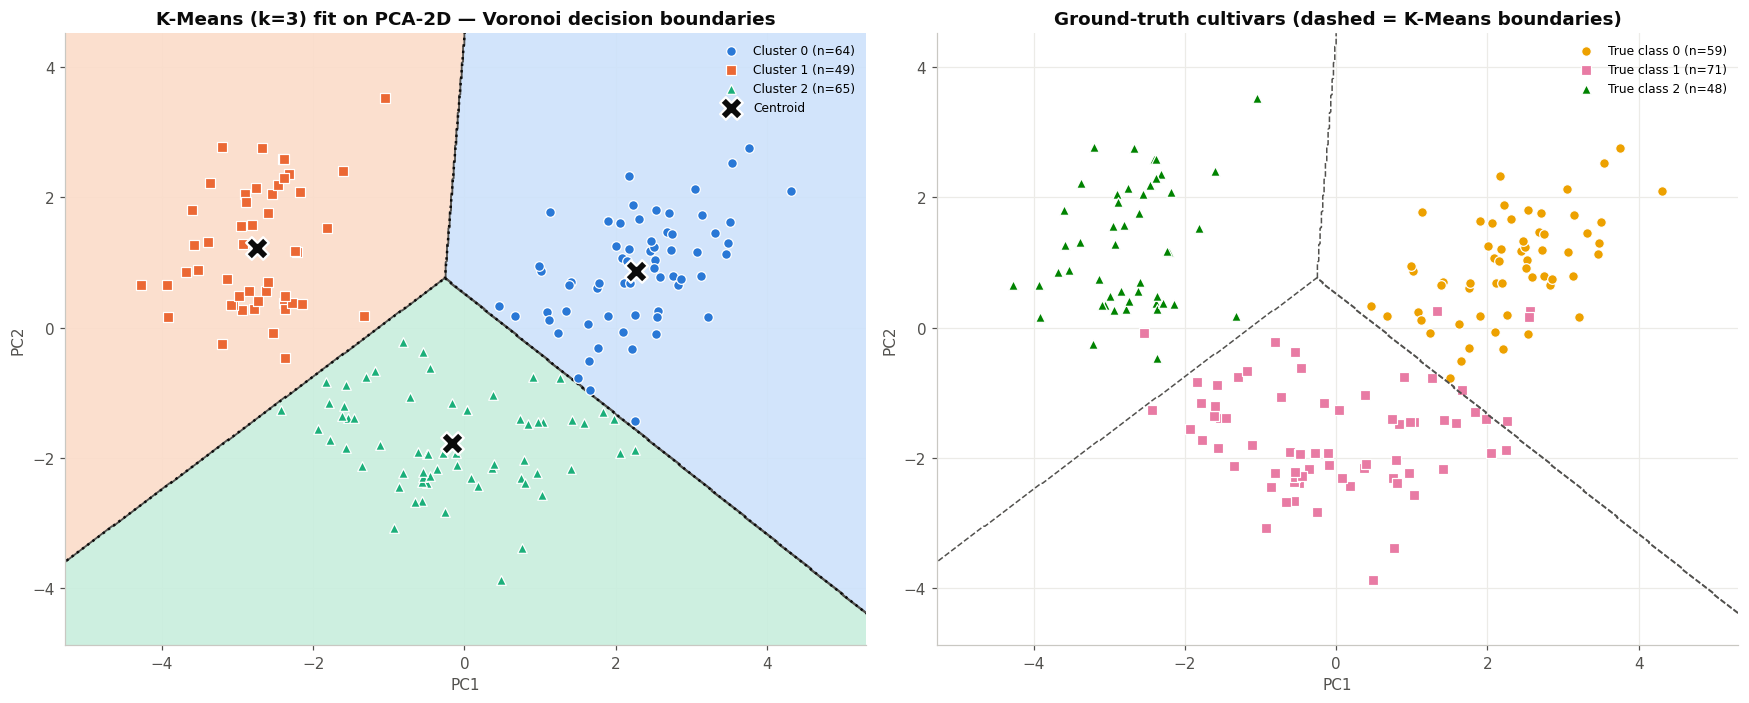


ARI (K-Means on PCA-2D vs. true classes): 0.8951
True class           0   1   2
2D K-Means cluster            
0                   59   5   0
1                    0   1  48
2                    0  65   0


In [4]:
from scipy.spatial import Voronoi

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_
print(f"Explained variance ratio: PC1 = {evr[0]:.3%}, PC2 = {evr[1]:.3%}, total = {evr.sum():.3%}")

loadings = pd.DataFrame(pca.components_.T, index=wine.feature_names, columns=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(f"Top loadings {pc}: " + ", ".join(f"{f} ({loadings.loc[f, pc]:+.2f})" for f in top))

kmeans_2d = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
centers_2d = kmeans_2d.cluster_centers_

pad = 1.0
x_min, x_max = X_pca[:, 0].min() - pad, X_pca[:, 0].max() + pad
y_min, y_max = X_pca[:, 1].min() - pad, X_pca[:, 1].max() + pad
xx, yy_ = np.meshgrid(np.linspace(x_min, x_max, 600), np.linspace(y_min, y_max, 600))
Z = kmeans_2d.predict(np.c_[xx.ravel(), yy_.ravel()]).reshape(xx.shape)

region_cmap = plt.matplotlib.colors.ListedColormap(["#cde2fb", "#fbdcc9", "#c8eedd"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
ax = axes[0]
ax.contourf(xx, yy_, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=region_cmap, alpha=0.9)
ax.contour(xx, yy_, Z, levels=[0.5, 1.5], colors=INK2, linewidths=1.2)

# geometric Voronoi ridges from the centroids (cross-check). Add far-away dummy points so all ridges are finite.
far = 1e3
vor = Voronoi(np.vstack([centers_2d, [[far, far], [-far, far], [far, -far], [-far, -far]]]))
for (p, q), rv in zip(vor.ridge_points, vor.ridge_vertices):
    if p < 3 and q < 3 and -1 not in rv:
        v = vor.vertices[rv]
        ax.plot(v[:, 0], v[:, 1], ":", color=INK, lw=1.6)

scatter_clusters(ax, X_pca, kmeans_2d.labels_, "K-Means (k=3) fit on PCA-2D — Voronoi decision boundaries",
                 centers=centers_2d)
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)

ax = axes[1]
for c in range(3):
    m = y == c
    ax.scatter(X_pca[m, 0], X_pca[m, 1], c=CLUSTER_COLORS[c + 3], marker=CLUSTER_MARKERS[c], s=40,
               edgecolors="white", linewidths=0.8, label=f"True class {c} (n={m.sum()})")
ax.contour(xx, yy_, Z, levels=[0.5, 1.5], colors=INK2, linewidths=1.0, linestyles="--")
ax.set_xlim(x_min, x_max); ax.set_ylim(y_min, y_max)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Ground-truth cultivars (dashed = K-Means boundaries)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"\nARI (K-Means on PCA-2D vs. true classes): {adjusted_rand_score(y, kmeans_2d.labels_):.4f}")
print(pd.crosstab(pd.Series(kmeans_2d.labels_, name="2D K-Means cluster"), pd.Series(y, name="True class")))

**Task 4: Soft Clustering with Distance Profiles of 5 Representative Wines**

What this code cell does:

K-Means puts each wine in exactly one cluster, but the model also knows how far each wine is from every centroid. Those distances can serve as a "soft" clustering that shows how strongly a wine belongs to each group, the same idea as the customer-segmentation resource notebook. Using the 13-feature K-Means model (k = 3) from Task 2, the cell picks five wines that show the full range of behaviour. Three are "prototypes," the wine closest to each centroid, which should be near one centroid and far from the others. Two are "borderline" wines, almost equally close to two centroids, so their cluster assignment is fragile. For these five wines, the cell computes the distance to each of the three centroids. It also converts those distances into membership probabilities with a softmax, so each wine's profile reads as a percentage of belonging to each cluster.
The distances are shown as an annotated heatmap, light for close and dark for far, with each wine's smallest distance (its hard K-Means assignment) outlined in orange. Each row label gives the wine's index, its role, its assigned cluster and its true cultivar. A second heatmap shows the membership probabilities for the same five wines.


Distance matrix (standardized 13-D Euclidean distance to each centroid):
           Centroid 0  Centroid 1  Centroid 2        role  hard cluster  margin  true class
Wine #106       1.548       4.268       4.305   prototype             0   2.721           1
Wine #148       4.495       1.079       5.298   prototype             1   3.415           2
Wine #48        3.815       4.869       1.343   prototype             2   2.472           0
Wine #61        3.521       3.397       5.250  borderline             1   0.124           1
Wine #121       6.327       7.476       6.162  borderline             2   0.165           1

Soft memberships (softmax of negative distance):
           Centroid 0  Centroid 1  Centroid 2
Wine #106       0.886       0.058       0.056
Wine #148       0.031       0.955       0.014
Wine #48        0.076       0.026       0.898
Wine #61        0.433       0.490       0.077
Wine #121       0.401       0.127       0.472


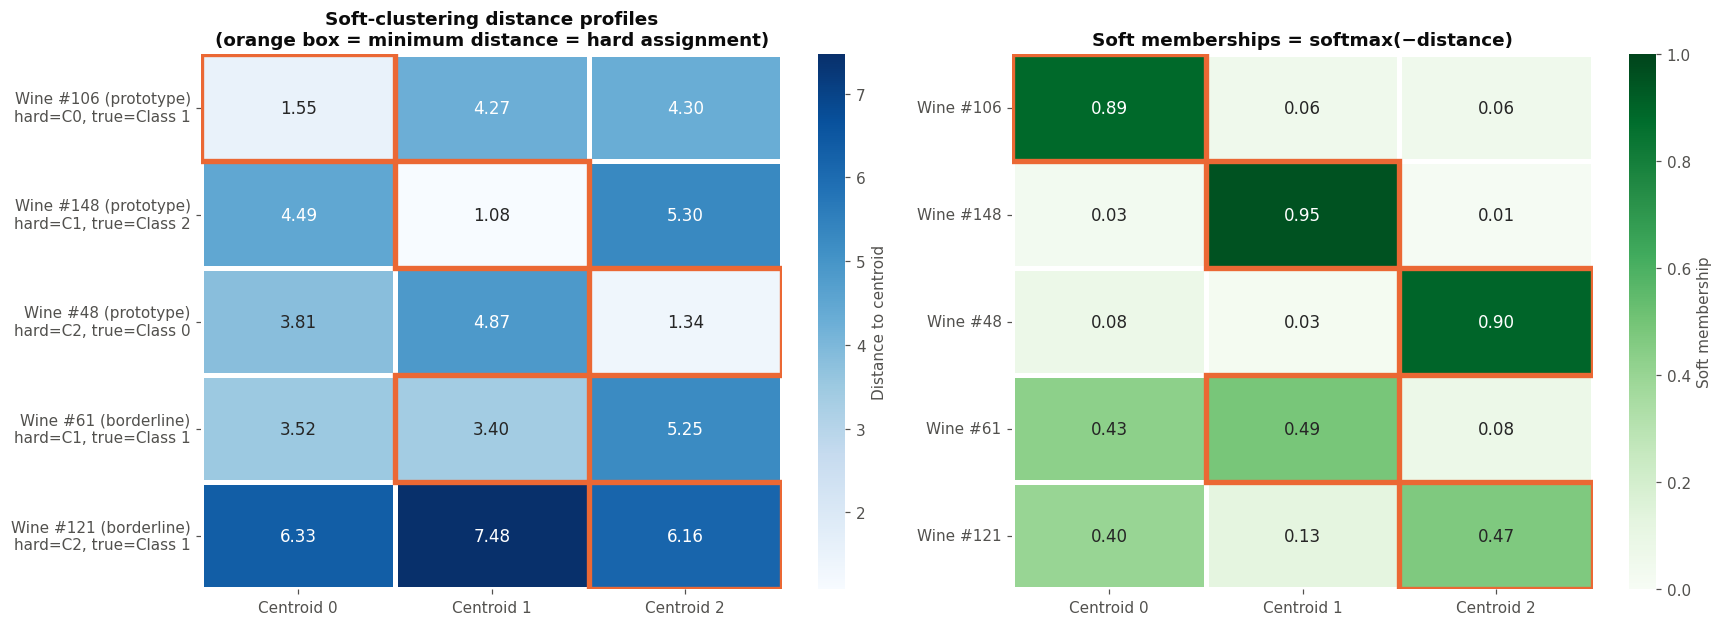

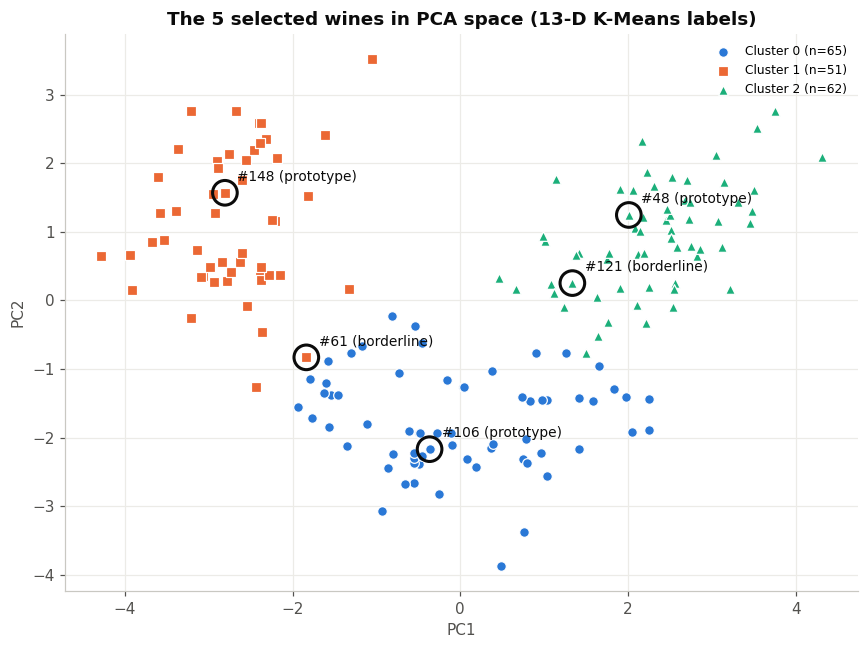

In [5]:
D_all = kmeans_13d.transform(X_scaled)            # (178, 3) distances to the 3 centroids
sorted_D = np.sort(D_all, axis=1)
margin = sorted_D[:, 1] - sorted_D[:, 0]         # gap between nearest and 2nd-nearest centroid

prototypes = [int(np.argmin(np.where(km_labels == c, D_all[:, c], np.inf))) for c in range(3)]
borderline = [int(i) for i in np.argsort(margin) if i not in prototypes][:2]
sample_idx = prototypes + borderline
roles = ["prototype"] * 3 + ["borderline"] * 2

D_sel = D_all[sample_idx]
hard = D_sel.argmin(axis=1)
soft = np.exp(-D_sel) / np.exp(-D_sel).sum(axis=1, keepdims=True)

row_labels = [f"Wine #{i} ({r})\nhard=C{h}, true=Class {y[i]}" for i, r, h in zip(sample_idx, roles, hard)]
col_labels = [f"Centroid {c}" for c in range(3)]

dist_df = pd.DataFrame(D_sel, index=[f"Wine #{i}" for i in sample_idx], columns=col_labels).round(3)
dist_df["role"] = roles
dist_df["hard cluster"] = hard
dist_df["margin"] = margin[sample_idx].round(3)
dist_df["true class"] = y[sample_idx]
print("Distance matrix (standardized 13-D Euclidean distance to each centroid):")
print(dist_df.to_string())

print("\nSoft memberships (softmax of negative distance):")
print(pd.DataFrame(soft, index=[f"Wine #{i}" for i in sample_idx], columns=col_labels).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(D_sel, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "Distance to centroid"},
            xticklabels=col_labels, yticklabels=row_labels, linewidths=2, linecolor="white", ax=axes[0],
            annot_kws={"fontsize": 11})
for r, c in enumerate(hard):
    axes[0].add_patch(mpatches.Rectangle((c, r), 1, 1, fill=False, edgecolor="#eb6834", lw=3.5))
axes[0].set_title("Soft-clustering distance profiles\n(orange box = minimum distance = hard assignment)")
axes[0].tick_params(axis="y", rotation=0)

sns.heatmap(soft, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, cbar_kws={"label": "Soft membership"},
            xticklabels=col_labels, yticklabels=[f"Wine #{i}" for i in sample_idx], linewidths=2,
            linecolor="white", ax=axes[1], annot_kws={"fontsize": 11})
for r, c in enumerate(hard):
    axes[1].add_patch(mpatches.Rectangle((c, r), 1, 1, fill=False, edgecolor="#eb6834", lw=3.5))
axes[1].set_title("Soft memberships = softmax(−distance)")
axes[1].tick_params(axis="y", rotation=0)
plt.tight_layout(); plt.show()

# where do the five samples lie in the 2D PCA picture?
fig, ax = plt.subplots(figsize=(8, 6))
scatter_clusters(ax, X_pca, km_labels, "The 5 selected wines in PCA space (13-D K-Means labels)")
for i, r in zip(sample_idx, roles):
    ax.scatter(*X_pca[i], s=260, facecolors="none", edgecolors=INK, lw=2, zorder=5)
    ax.annotate(f"#{i} ({r})", X_pca[i], xytext=(8, 8), textcoords="offset points", fontsize=9, color=INK)
plt.tight_layout(); plt.show()

**Task 5: DBSCAN on the 13-D Standardized Feature Space**

What this code cell does:

DBSCAN doesn't need the number of clusters. Instead it uses two settings: eps, a neighbourhood radius, and min_samples, the number of points a neighbourhood must contain. A wine with at least min_samples neighbours within eps is a core point, and nearby core points link into clusters. Wines within reach of a core point join its cluster as border points, and everything else is labelled noise. To choose eps, the cell plots each wine's distance to its min_samples-th nearest neighbour in sorted order and looks for the "knee" where distances shoot up. Because 178 wines in 13 dimensions are spread thinly, DBSCAN is very sensitive to its settings. The cell therefore tests eps from 1.8 to 3.0 and min_samples from 3 to 10, recording the number of clusters, the noise count and the ARI for each combination. The ARI is only reported, never used for fitting, and two heatmaps summarize the grid.
The final model uses eps = 2.3 and min_samples = 3. That setting sits near the knee of the curve and is the largest eps that still produces more than two groups instead of one giant cluster. The grid shows DBSCAN's core weakness. At eps 2.0 or below the data break into many small clusters with heavy noise, while at 2.5 or above one cluster swallows almost everything. No setting finds three clusters of similar size, because two cultivars are linked by a chain of moderately dense wines. The best result is two large clusters, plus a tiny 3-wine cluster at this setting. The cell prints the number of clusters, noise points and core points, along with a cross-tabulation against the true classes. It then plots the 13-D results on the 2D PCA view, with core points as filled markers, border points as hollow markers and noise as gray X markers. Some noise points look like they sit inside a cluster in 2D because they are far from their neighbours along dimensions PCA doesn't show.


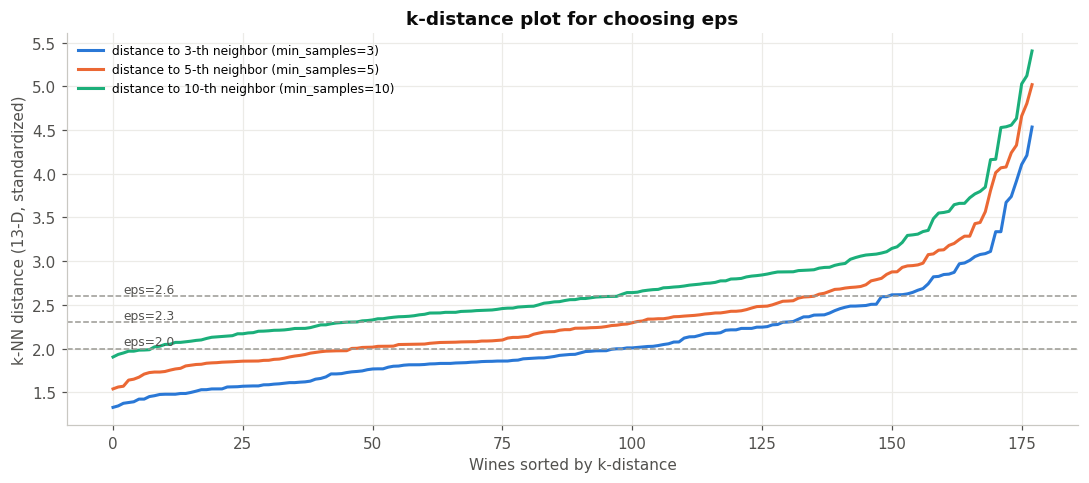

DBSCAN hyperparameter experiment (ARI is for reporting only — labels are never used for fitting):
 eps  min_samples  n_clusters  n_noise  noise_%    ARI
 1.8            3           8       90     50.6  0.241
 1.8            4           9      103     57.9  0.105
 1.8            5           7      118     66.3  0.084
 1.8            8           1      170     95.5  0.028
 1.8           10           0      178    100.0  0.000
 2.0            3           5       64     36.0  0.287
 2.0            4           6       66     37.1  0.258
 2.0            5           5       85     47.8  0.220
 2.0            8           3      117     65.7  0.288
 2.0           10           1      139     78.1  0.243
 2.2            3           3       44     24.7  0.387
 2.2            4           2       48     27.0  0.378
 2.2            5           2       55     30.9  0.329
 2.2            8           2       67     37.6  0.289
 2.2           10           2       89     50.0  0.260
 2.3            3     

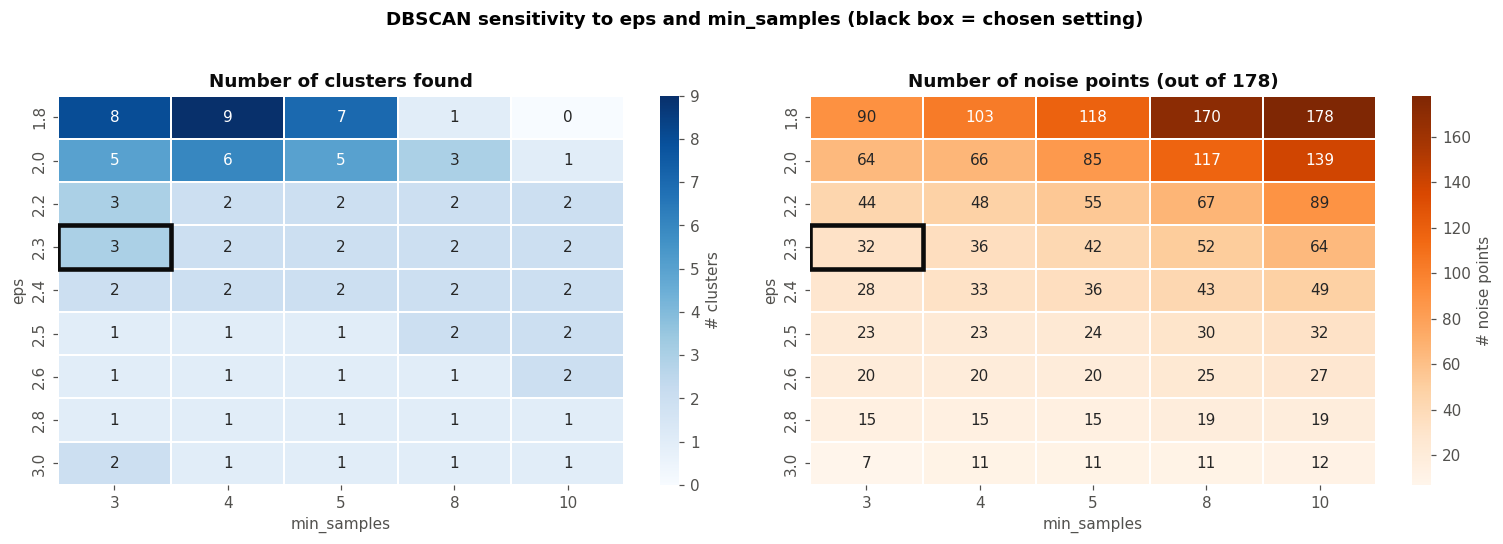


FINAL DBSCAN: eps = 2.3, min_samples = 3
Number of clusters identified : 3
Number of noise points        : 32  (18.0% of wines)
Core points                   : 129
Border points                 : 17
Cluster sizes                 : {0: np.int64(100), 1: np.int64(3), 2: np.int64(43)}
ARI vs. true classes          : 0.3994

Cross-tabulation DBSCAN vs. true cultivar (-1 = noise):
True class     0   1   2
DBSCAN label            
-1             3  23   6
 0            56  44   0
 1             0   3   0
 2             0   1  42


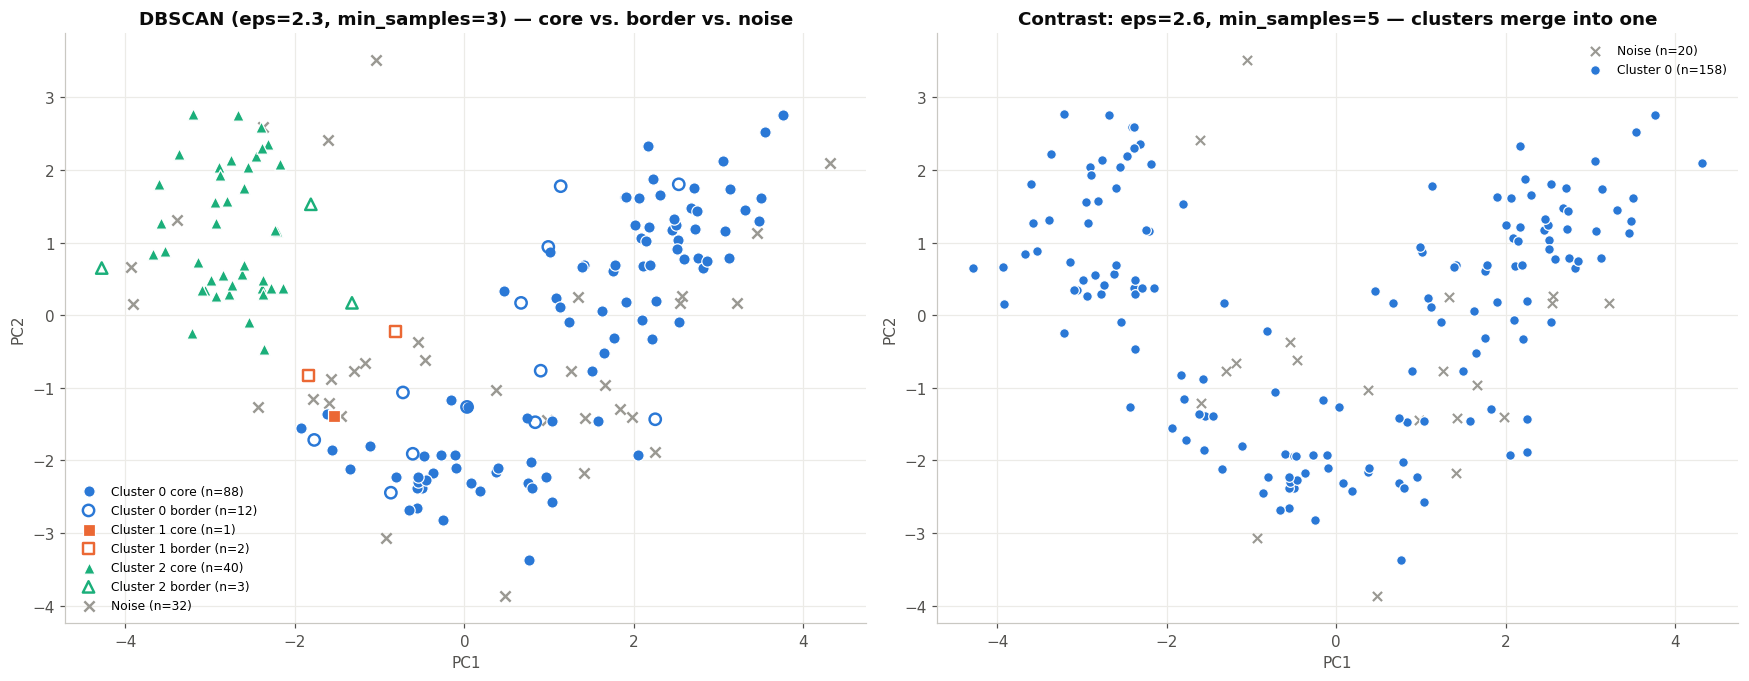

In [6]:
# ---------------- Step 1: k-distance plot ----------------
fig, ax = plt.subplots(figsize=(10, 4.5))
for ms, col in zip([3, 5, 10], ["#2a78d6", "#eb6834", "#1baf7a"]):
    nn = NearestNeighbors(n_neighbors=ms).fit(X_scaled)
    kd = np.sort(nn.kneighbors(X_scaled)[0][:, -1])
    ax.plot(kd, color=col, lw=2, label=f"distance to {ms}-th neighbor (min_samples={ms})")
for e in [2.0, 2.3, 2.6]:
    ax.axhline(e, ls="--", lw=1, color=NOISE_COLOR)
    ax.text(2, e + 0.04, f"eps={e}", color=INK2, fontsize=8)
ax.set_xlabel("Wines sorted by k-distance"); ax.set_ylabel("k-NN distance (13-D, standardized)")
ax.set_title("k-distance plot for choosing eps"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---------------- Step 2: hyperparameter grid ----------------
eps_grid = [1.8, 2.0, 2.2, 2.3, 2.4, 2.5, 2.6, 2.8, 3.0]
ms_grid = [3, 4, 5, 8, 10]
rows = []
for e in eps_grid:
    for ms in ms_grid:
        lab = DBSCAN(eps=e, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        rows.append({"eps": e, "min_samples": ms, "n_clusters": n_cl, "n_noise": int((lab == -1).sum()),
                     "noise_%": round(100 * (lab == -1).mean(), 1), "ARI": round(adjusted_rand_score(y, lab), 3)})
grid = pd.DataFrame(rows)
print("DBSCAN hyperparameter experiment (ARI is for reporting only — labels are never used for fitting):")
print(grid.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(grid.pivot(index="eps", columns="min_samples", values="n_clusters"), annot=True, fmt="d",
            cmap="Blues", ax=axes[0], cbar_kws={"label": "# clusters"}, linewidths=1, linecolor="white")
axes[0].set_title("Number of clusters found")
sns.heatmap(grid.pivot(index="eps", columns="min_samples", values="n_noise"), annot=True, fmt="d",
            cmap="Oranges", ax=axes[1], cbar_kws={"label": "# noise points"}, linewidths=1, linecolor="white")
axes[1].set_title("Number of noise points (out of 178)")
for a in axes:
    r = eps_grid.index(2.3); c = ms_grid.index(3)
    a.add_patch(mpatches.Rectangle((c, r), 1, 1, fill=False, edgecolor=INK, lw=3))
plt.suptitle("DBSCAN sensitivity to eps and min_samples (black box = chosen setting)", y=1.02,
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# ---------------- Step 3: final model ----------------
DB_EPS, DB_MS = 2.3, 3
dbscan = DBSCAN(eps=DB_EPS, min_samples=DB_MS).fit(X_scaled)
db_labels = dbscan.labels_
core_mask = np.zeros(len(db_labels), bool); core_mask[dbscan.core_sample_indices_] = True
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_db_noise = int((db_labels == -1).sum())

print("\n" + "=" * 70)
print(f"FINAL DBSCAN: eps = {DB_EPS}, min_samples = {DB_MS}")
print("=" * 70)
print(f"Number of clusters identified : {n_db_clusters}")
print(f"Number of noise points        : {n_db_noise}  ({n_db_noise / len(db_labels):.1%} of wines)")
print(f"Core points                   : {core_mask.sum()}")
print(f"Border points                 : {((~core_mask) & (db_labels != -1)).sum()}")
print(f"Cluster sizes                 : {dict(pd.Series(db_labels[db_labels != -1]).value_counts().sort_index())}")
print(f"ARI vs. true classes          : {adjusted_rand_score(y, db_labels):.4f}")
print("\nCross-tabulation DBSCAN vs. true cultivar (-1 = noise):")
print(pd.crosstab(pd.Series(db_labels, name="DBSCAN label"), pd.Series(y, name="True class")))

# ---------------- Step 4: visualize on PCA-2D ----------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6.3))
ax = axes[0]
for c in sorted(set(db_labels) - {-1}):
    m_core = (db_labels == c) & core_mask
    m_border = (db_labels == c) & ~core_mask
    ax.scatter(X_pca[m_core, 0], X_pca[m_core, 1], c=CLUSTER_COLORS[c], marker=CLUSTER_MARKERS[c], s=55,
               edgecolors="white", linewidths=0.8, label=f"Cluster {c} core (n={m_core.sum()})", zorder=3)
    ax.scatter(X_pca[m_border, 0], X_pca[m_border, 1], facecolors="none", edgecolors=CLUSTER_COLORS[c],
               marker=CLUSTER_MARKERS[c], s=55, linewidths=1.6, label=f"Cluster {c} border (n={m_border.sum()})", zorder=3)
m = db_labels == -1
ax.scatter(X_pca[m, 0], X_pca[m, 1], c=NOISE_COLOR, marker="x", s=45, linewidths=1.6,
           label=f"Noise (n={m.sum()})", zorder=2)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)
ax.set_title(f"DBSCAN (eps={DB_EPS}, min_samples={DB_MS}) — core vs. border vs. noise")

# compare with a 'too large eps' setting that merges clusters
alt = DBSCAN(eps=2.6, min_samples=5).fit_predict(X_scaled)
scatter_clusters(axes[1], X_pca, alt, "Contrast: eps=2.6, min_samples=5 — clusters merge into one")
plt.tight_layout(); plt.show()

**Task 6: HDBSCAN on the 13-D Standardized Feature Space**

What this code cell does:
HDBSCAN removes the need to choose a single eps. In effect, it runs DBSCAN at every density level and keeps the clusters that stay stable across the widest range. Its main setting is min_cluster_size, the smallest group that counts as a cluster, set to 5 as the assignment requires. Its other setting, min_samples, defaults to the same value. The algorithm first measures each wine's local density as the distance to its 5th nearest neighbour. It then adjusts the distances between wines so that sparse wines are pushed away while dense regions stay unchanged. From these adjusted distances it builds a cluster hierarchy, which Task 7 visualizes. It ignores splits smaller than min_cluster_size and keeps the set of clusters that hold their wines across the widest range of densities. Wines that never fall in a selected cluster are labelled noise.
The cell prints the number of clusters and noise points, the cluster sizes, the ARI and a cross-tabulation against the true classes. It also summarizes each wine's membership strength, a 0-to-1 score HDBSCAN gives for how firmly a wine belongs to its cluster. Two side-by-side PCA plots show the clusters with noise as gray X markers, and the same clusters sized by membership strength, which shows the weaker members sitting on the cluster edges. Finally, a sensitivity check reruns HDBSCAN with min_cluster_size from 3 to 20 to show how robust the result is.


HDBSCAN (min_cluster_size = 5; min_samples defaults to 5)
Total clusters discovered : 2
Noise points detected     : 58  (32.6% of wines)
Cluster sizes             : {0: np.int64(86), 1: np.int64(34)}
ARI vs. true classes      : 0.3422

Cross-tabulation HDBSCAN vs. true cultivar (-1 = noise):
True class      0   1   2
HDBSCAN label            
-1              6  37  15
 0             53  33   0
 1              0   1  33

Membership strength (probabilities_) per cluster:
    count   mean    min    50%  max
-1   58.0  0.000  0.000  0.000  0.0
 0   86.0  0.953  0.824  0.984  1.0
 1   34.0  0.971  0.890  1.000  1.0


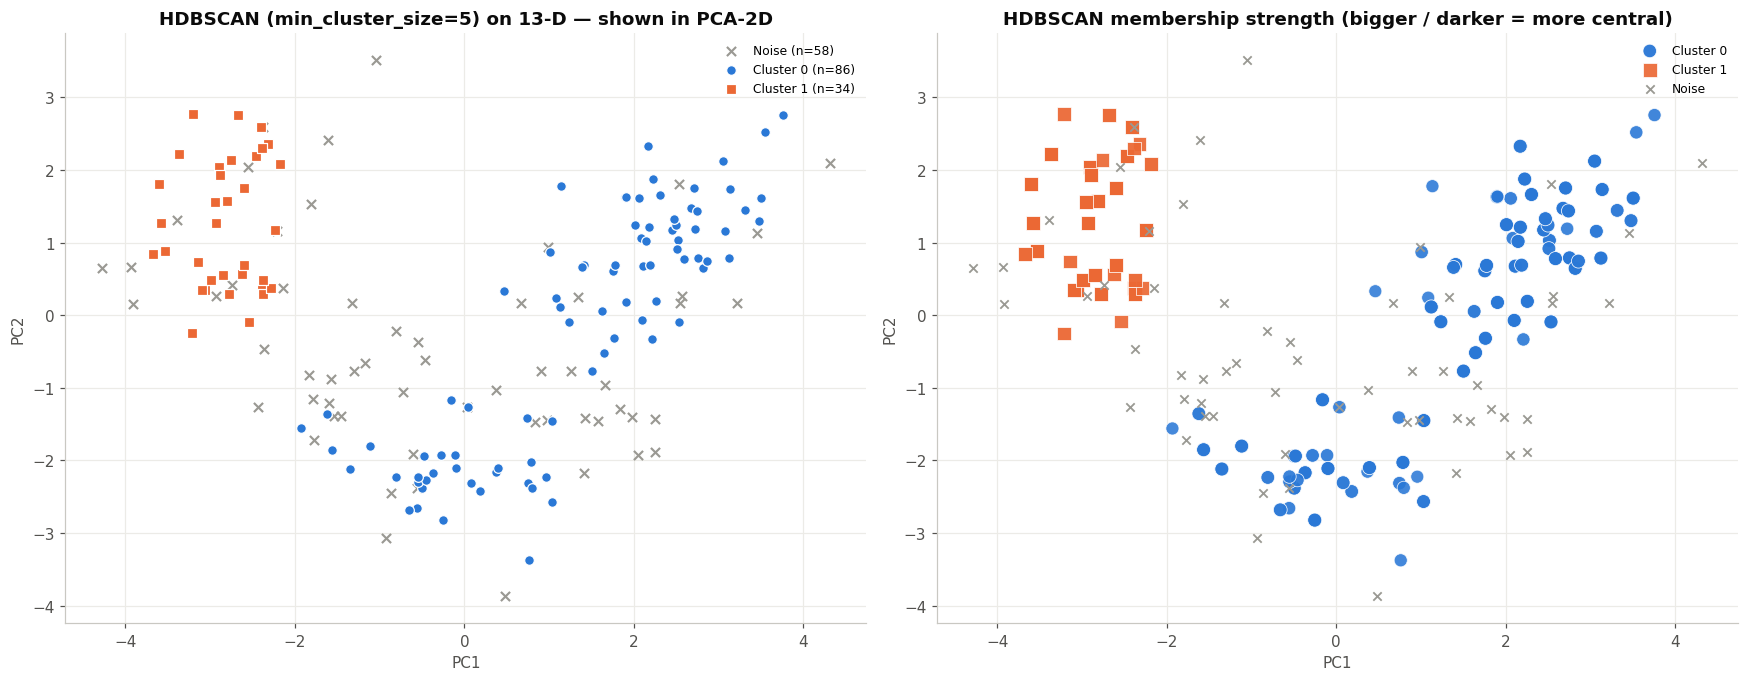


HDBSCAN sensitivity to min_cluster_size:
 min_cluster_size  n_clusters  n_noise    ARI
                3           2        3 -0.009
                5           2       58  0.342
               10           2       75  0.260
               15           2       82  0.228
               20           0      178  0.000


In [7]:
hdb = HDBSCAN(min_cluster_size=5, copy=True).fit(X_scaled)
hdb_labels = hdb.labels_
hdb_prob = hdb.probabilities_
n_hdb_clusters = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
n_hdb_noise = int((hdb_labels == -1).sum())

print("=" * 70)
print("HDBSCAN (min_cluster_size = 5; min_samples defaults to 5)")
print("=" * 70)
print(f"Total clusters discovered : {n_hdb_clusters}")
print(f"Noise points detected     : {n_hdb_noise}  ({n_hdb_noise / len(hdb_labels):.1%} of wines)")
print(f"Cluster sizes             : {dict(pd.Series(hdb_labels[hdb_labels != -1]).value_counts().sort_index())}")
print(f"ARI vs. true classes      : {adjusted_rand_score(y, hdb_labels):.4f}")
print("\nCross-tabulation HDBSCAN vs. true cultivar (-1 = noise):")
print(pd.crosstab(pd.Series(hdb_labels, name="HDBSCAN label"), pd.Series(y, name="True class")))
print("\nMembership strength (probabilities_) per cluster:")
print(pd.Series(hdb_prob).groupby(hdb_labels).describe()[["count", "mean", "min", "50%", "max"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.3))
scatter_clusters(axes[0], X_pca, hdb_labels, "HDBSCAN (min_cluster_size=5) on 13-D — shown in PCA-2D")
ax = axes[1]
for c in sorted(set(hdb_labels) - {-1}):
    m = hdb_labels == c
    ax.scatter(X_pca[m, 0], X_pca[m, 1], s=15 + 70 * hdb_prob[m], c=CLUSTER_COLORS[c], marker=CLUSTER_MARKERS[c],
               alpha=np.clip(0.25 + 0.75 * hdb_prob[m], 0, 1), edgecolors="white", linewidths=0.5,
               label=f"Cluster {c}")
m = hdb_labels == -1
ax.scatter(X_pca[m, 0], X_pca[m, 1], c=NOISE_COLOR, marker="x", s=30, linewidths=1.2, label="Noise")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)
ax.set_title("HDBSCAN membership strength (bigger / darker = more central)")
plt.tight_layout(); plt.show()

sens = []
for mcs in [3, 5, 10, 15, 20]:
    lab = HDBSCAN(min_cluster_size=mcs, copy=True).fit_predict(X_scaled)
    sens.append({"min_cluster_size": mcs, "n_clusters": len(set(lab)) - (1 if -1 in lab else 0),
                 "n_noise": int((lab == -1).sum()), "ARI": round(adjusted_rand_score(y, lab), 3)})
print("\nHDBSCAN sensitivity to min_cluster_size:")
print(pd.DataFrame(sens).to_string(index=False))

**Task 7: Single-Linkage Hierarchical Clustering Dendrogram**

What this code cell does:
Single-linkage clustering starts with each wine as its own cluster and repeatedly merges the two clusters whose closest members are nearest to each other. The cell records every merge in a linkage matrix and prints its first and last rows. It then draws three figures. The first is a dendrogram on ordinary distances, with each wine coloured by its true cultivar and bar heights showing when groups merge. It shows the "chaining" typical of single linkage, where wines join one at a time instead of in clean blocks. Dashed lines show what cutting the tree at one fixed distance would produce, which is essentially what DBSCAN does. The second dendrogram is built on HDBSCAN's adjusted distances (using each wine's 5th-nearest-neighbour distance). This reproduces the exact hierarchy HDBSCAN builds internally, and in it sparse wines merge later, which reduces chaining through low-density gaps.
The third figure counts how many clusters of at least 5 wines each cut height produces. No single cut gives three clean groups. Low cuts leave most wines in tiny fragments, high cuts give one or two giant clusters, and even the cut that yields three groups leaves dozens of wines stranded. HDBSCAN avoids this by not using a single cut. It ignores splits smaller than min_cluster_size and keeps the clusters that persist longest, which can sit at different heights in different branches of the tree.


Linkage matrix shape: (177, 4)  (n-1 merges x [cluster_i, cluster_j, distance, new_size])

First 5 merges:
   cluster_i  cluster_j  distance  size
0        9.0       47.0     1.164   2.0
1      131.0      133.0     1.192   2.0
2       11.0       12.0     1.209   2.0
3       15.0       53.0     1.226   2.0
4       92.0      107.0     1.245   2.0

Last 5 merges:
   cluster_i  cluster_j  distance   size
0      110.0      349.0     3.429  172.0
1       59.0      350.0     3.641  173.0
2      121.0      351.0     3.860  174.0
3       73.0      352.0     3.908  175.0
4      347.0      353.0     4.003  178.0


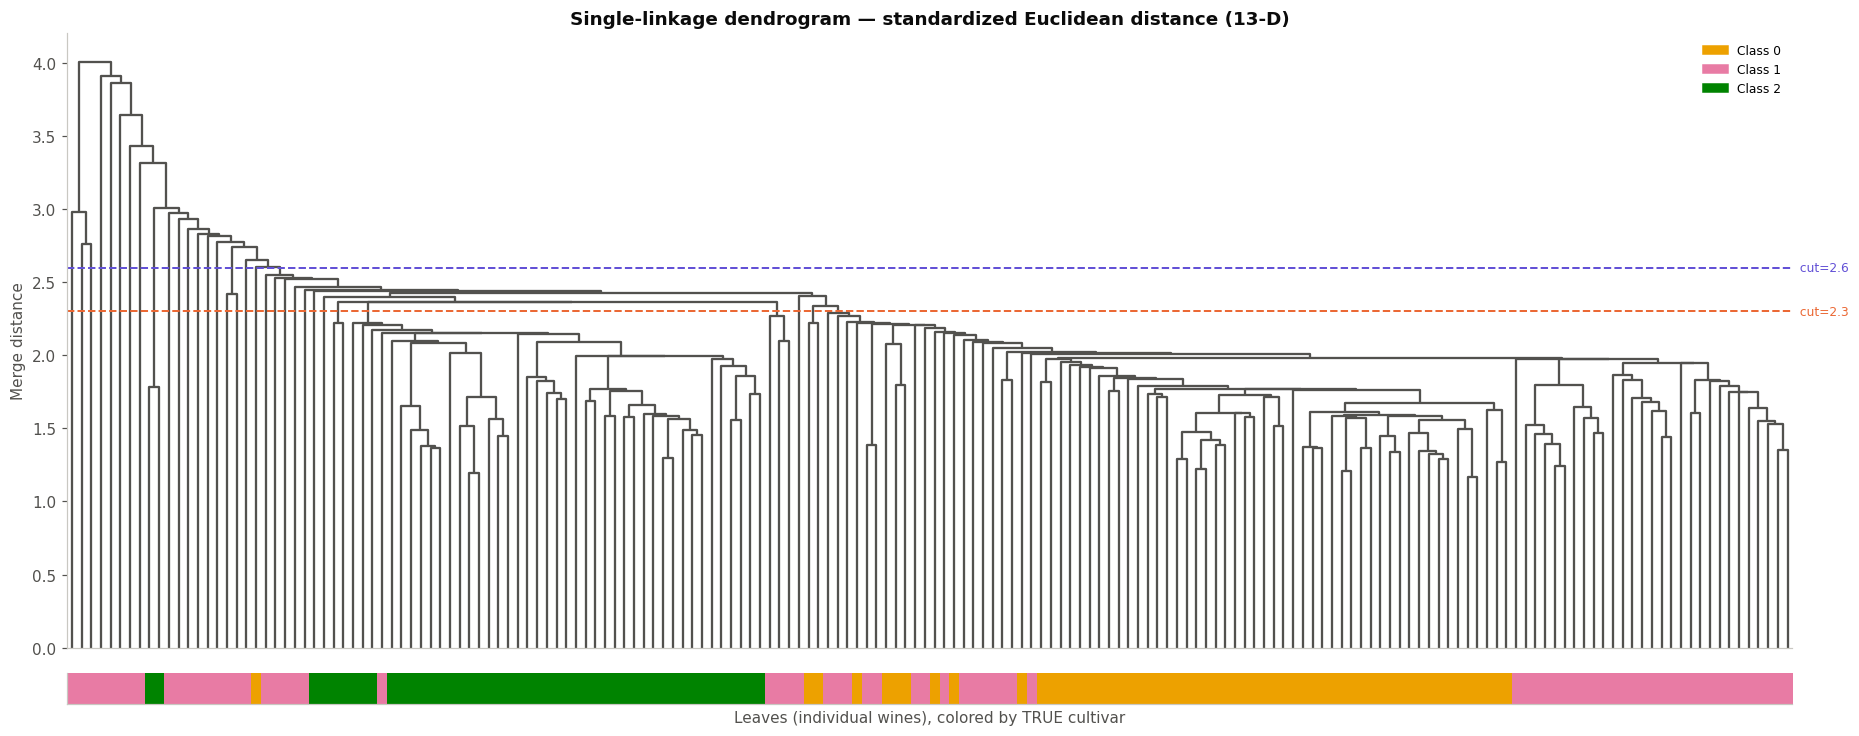

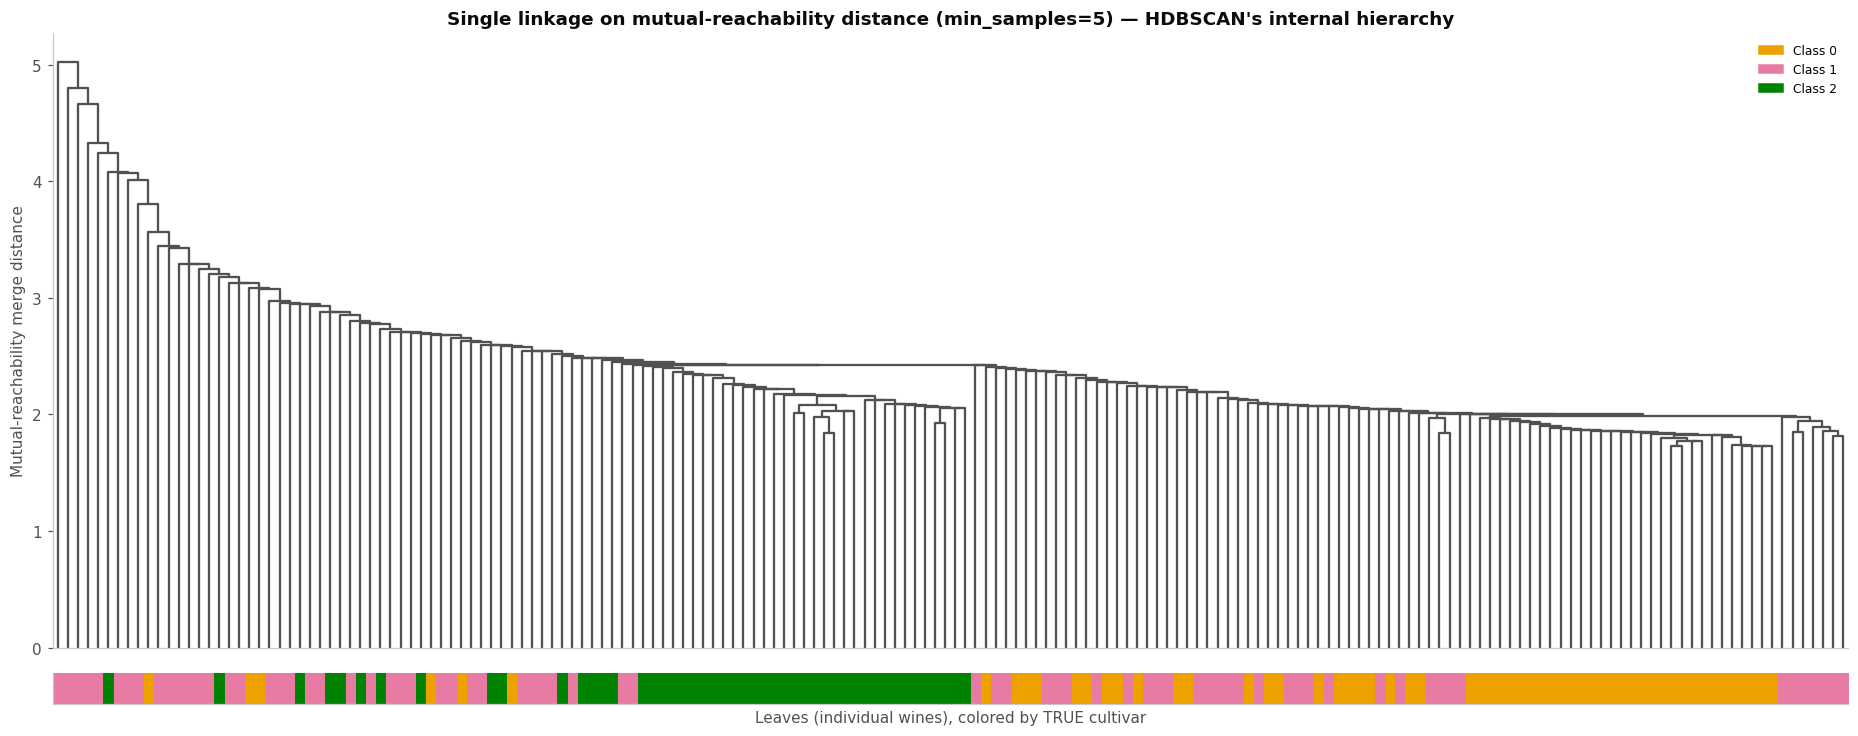

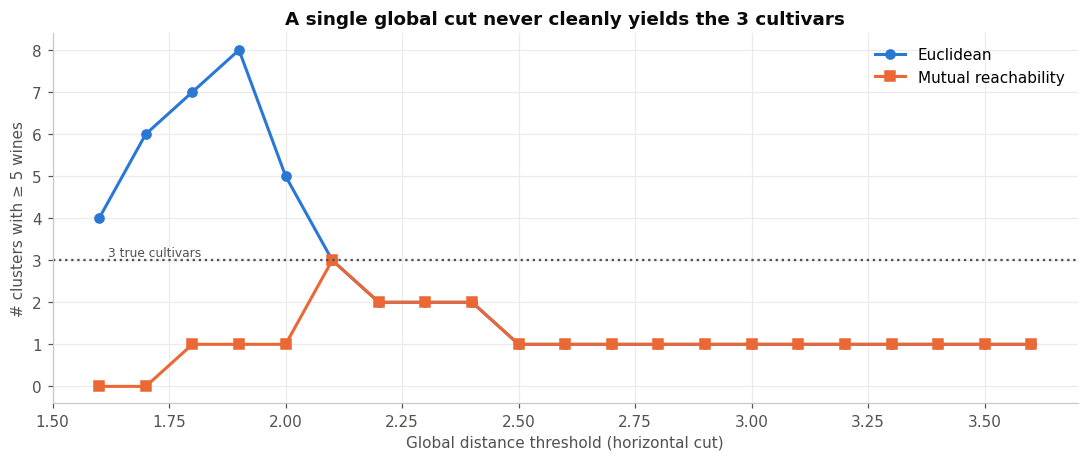

     tree  cut  clusters_>=5  largest  points_in_small(<5)
Euclidean  1.6             4       16                  144
Euclidean  1.7             6       22                  123
Euclidean  1.8             7       39                   93
Euclidean  1.9             8       43                   79
Euclidean  2.0             5       78                   64
Euclidean  2.1             3       85                   55
Euclidean  2.2             2       90                   47
Euclidean  2.3             2      100                   35
Euclidean  2.4             2      102                   28
Euclidean  2.5             1      155                   23
Euclidean  2.6             1      158                   20
Euclidean  2.7             1      160                   18
Euclidean  2.8             1      163                   15
Euclidean  2.9             1      166                   12
Euclidean  3.0             1      168                   10
Euclidean  3.1             1      170                   

In [8]:
Z = linkage(X_scaled, method="single", metric="euclidean")
print("Linkage matrix shape:", Z.shape, " (n-1 merges x [cluster_i, cluster_j, distance, new_size])")
print("\nFirst 5 merges:")
print(pd.DataFrame(Z[:5], columns=["cluster_i", "cluster_j", "distance", "size"]).round(3).to_string())
print("\nLast 5 merges:")
print(pd.DataFrame(Z[-5:], columns=["cluster_i", "cluster_j", "distance", "size"]).round(3).to_string())

def dendro_with_classes(Zm, title, ylabel, cuts=()):
    fig, (ax, axc) = plt.subplots(2, 1, figsize=(17, 6.8), gridspec_kw={"height_ratios": [12, 0.6]}, sharex=False)
    dn = dendrogram(Zm, ax=ax, color_threshold=0, above_threshold_color="#52514e", no_labels=True)
    for cut, col in cuts:
        ax.axhline(cut, ls="--", color=col, lw=1.3)
        ax.text(ax.get_xlim()[1] * 1.002, cut, f" cut={cut}", va="center", color=col, fontsize=8)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.grid(False)
    leaf_classes = y[dn["leaves"]]
    axc.imshow(leaf_classes[None, :], aspect="auto",
               cmap=plt.matplotlib.colors.ListedColormap(CLUSTER_COLORS[3:6]), interpolation="nearest")
    axc.set_yticks([]); axc.set_xticks([]); axc.set_xlabel("Leaves (individual wines), colored by TRUE cultivar")
    handles = [mpatches.Patch(color=CLUSTER_COLORS[3 + c], label=f"Class {c}") for c in range(3)]
    ax.legend(handles=handles, loc="upper right", fontsize=8)
    plt.tight_layout(); plt.show()

dendro_with_classes(Z, "Single-linkage dendrogram — standardized Euclidean distance (13-D)",
                    "Merge distance", cuts=[(2.3, "#eb6834"), (2.6, "#6250d6")])

# ---- HDBSCAN-style hierarchy: single linkage on mutual reachability distance ----
k_core = 5
core_d = NearestNeighbors(n_neighbors=k_core).fit(X_scaled).kneighbors(X_scaled)[0][:, -1]
D = squareform(pdist(X_scaled))
MR = np.maximum(D, np.maximum.outer(core_d, core_d))
np.fill_diagonal(MR, 0)
Z_mr = linkage(squareform(MR, checks=False), method="single")
dendro_with_classes(Z_mr, "Single linkage on mutual-reachability distance (min_samples=5) — HDBSCAN's internal hierarchy",
                    "Mutual-reachability merge distance")

# ---- how many sizeable clusters does each single global cut produce? ----
cuts = np.round(np.arange(1.6, 3.61, 0.1), 2)
rows = []
for name, ZZ in [("Euclidean", Z), ("Mutual reachability", Z_mr)]:
    for t in cuts:
        fl = fcluster(ZZ, t=t, criterion="distance")
        sizes = np.bincount(fl)[1:]
        rows.append({"tree": name, "cut": t, "clusters_>=5": int((sizes >= 5).sum()),
                     "largest": int(sizes.max()), "points_in_small(<5)": int(sizes[sizes < 5].sum())})
cut_df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.3))
for (name, g), col, mk in zip(cut_df.groupby("tree"), ["#2a78d6", "#eb6834"], ["o", "s"]):
    ax.plot(g["cut"], g["clusters_>=5"], marker=mk, color=col, lw=2, label=name)
ax.axhline(3, ls=":", color=INK2); ax.text(1.62, 3.1, "3 true cultivars", color=INK2, fontsize=8)
ax.set_xlabel("Global distance threshold (horizontal cut)"); ax.set_ylabel("# clusters with ≥ 5 wines")
ax.set_title("A single global cut never cleanly yields the 3 cultivars"); ax.legend()
plt.tight_layout(); plt.show()
print(cut_df[cut_df["tree"] == "Euclidean"].to_string(index=False))

**Task 8: Cluster Labels as Pseudo-Features for Supervised Classification**

What this code cell does:
This experiment measures how much each algorithm's clusters reveal about the true cultivar: if the clusters match the real groups, a classifier given only the cluster label should predict the cultivar well. The cell takes the labels from K-Means (k = 3), DBSCAN (eps 2.3, min_samples 3) and HDBSCAN (min_cluster_size 5) and turns each into one-hot features. Noise is kept as its own category, because those wines still need a prediction. There is no label leakage, since the clustering never saw the true labels. DBSCAN and HDBSCAN can't assign new points to clusters, so the clusters are computed once on all 178 wines before splitting. The data is then split 80/20 with stratification (142 training and 36 test wines), using the same split for every algorithm. A 300-tree Random Forest is trained on each algorithm's cluster features to predict the cultivar, and its accuracy is measured on the test set.
Two baselines frame the results: always predicting the most common class, and a Random Forest trained on all 13 original features. The cell also computes each algorithm's silhouette score. For DBSCAN and HDBSCAN, noise points are left out of the silhouette score, and the share excluded is reported, since a high score on a small subset means less than one on all wines. A bar chart compares accuracy and silhouette across the three algorithms, and confusion matrices show which cultivars each one mixes up.


Train: 142 wines, class counts [47 57 38]
Test : 36 wines, class counts [12 14 10]

Majority-class baseline accuracy        : 0.389
Upper bound (RF on all 13 scaled feats) : 1.000

               n_clusters  noise_points  Test accuracy  Silhouette (non-noise)  % points scored  ARI (all points)  Test noise points
Algorithm                                                                                                                           
K-Means (k=3)           3             0         0.9722                  0.2849         100.0000            0.8975                  0
DBSCAN                  3            32         0.7222                  0.2249          82.0225            0.3994                  5
HDBSCAN                 2            58         0.7500                  0.3524          67.4157            0.3422                 13


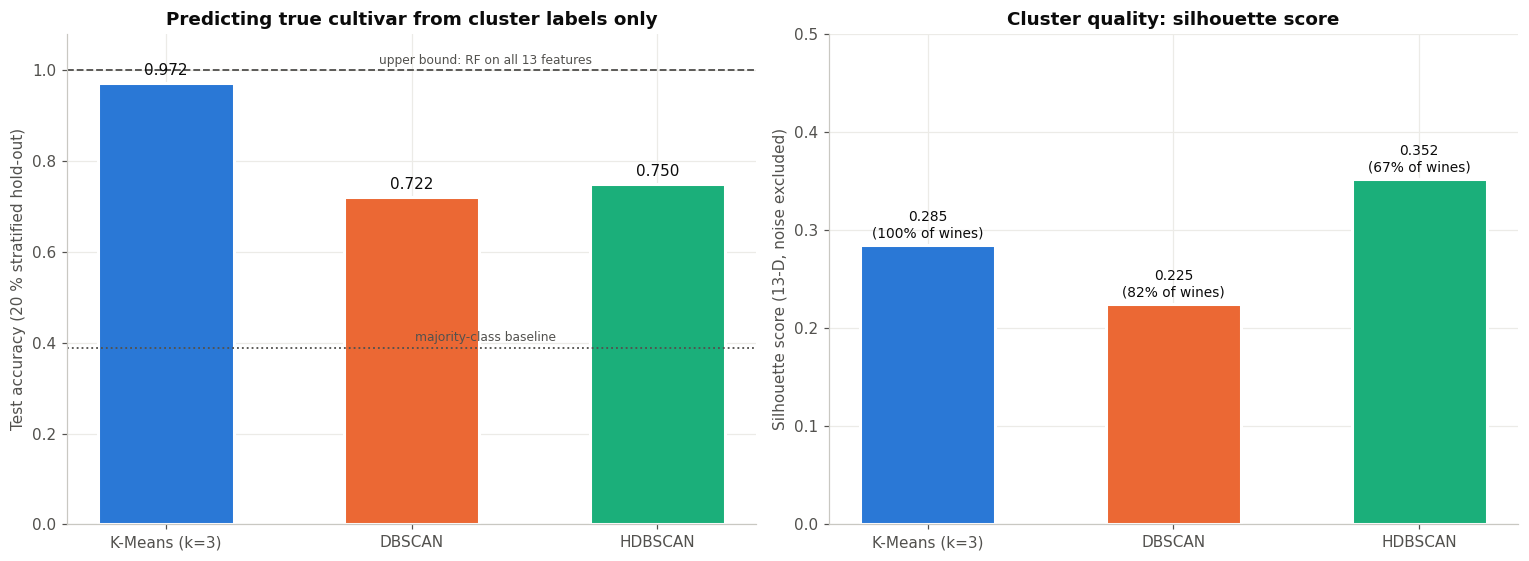

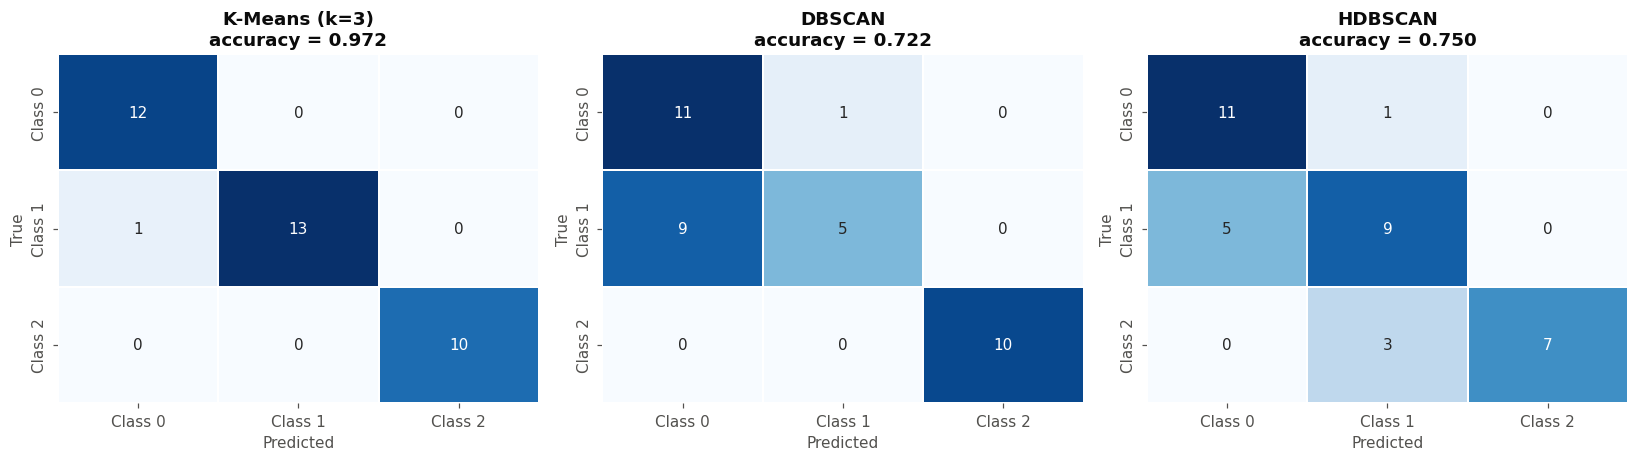

In [9]:
X_tr_idx, X_te_idx = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=RANDOM_STATE)
y_tr, y_te = y[X_tr_idx], y[X_te_idx]
print(f"Train: {len(X_tr_idx)} wines, class counts {np.bincount(y_tr)}")
print(f"Test : {len(X_te_idx)} wines, class counts {np.bincount(y_te)}")

label_sets = {"K-Means (k=3)": km_labels, "DBSCAN": db_labels, "HDBSCAN": hdb_labels}

results, cms = [], {}
for name, lab in label_sets.items():
    feat = pd.get_dummies(pd.Series(np.where(lab == -1, "noise", lab.astype(str))), prefix="cl").astype(int)
    clf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
    clf.fit(feat.iloc[X_tr_idx], y_tr)
    pred = clf.predict(feat.iloc[X_te_idx])
    acc = accuracy_score(y_te, pred)
    cms[name] = confusion_matrix(y_te, pred, labels=[0, 1, 2])

    mask = lab != -1
    sil = silhouette_score(X_scaled[mask], lab[mask]) if len(set(lab[mask])) > 1 else np.nan
    results.append({"Algorithm": name, "n_clusters": len(set(lab[mask])), "noise_points": int((~mask).sum()),
                    "Test accuracy": acc, "Silhouette (non-noise)": sil,
                    "% points scored": 100 * mask.mean(), "ARI (all points)": adjusted_rand_score(y, lab),
                    "Test noise points": int((lab[X_te_idx] == -1).sum())})

res = pd.DataFrame(results).set_index("Algorithm")

majority = (y_te == np.bincount(y_tr).argmax()).mean()
full_rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_scaled[X_tr_idx], y_tr)
upper = accuracy_score(y_te, full_rf.predict(X_scaled[X_te_idx]))
print(f"\nMajority-class baseline accuracy        : {majority:.3f}")
print(f"Upper bound (RF on all 13 scaled feats) : {upper:.3f}\n")
print(res.round(4).to_string())

# ---------------- plots ----------------
names = list(res.index)
cols = CLUSTER_COLORS[:3]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
b = axes[0].bar(names, res["Test accuracy"], color=cols, width=0.55, edgecolor="white", linewidth=2)
axes[0].axhline(upper, ls="--", color=INK2, lw=1.2); axes[0].text(1.3, upper + 0.015, "upper bound: RF on all 13 features", fontsize=8, color=INK2, ha="center")
axes[0].axhline(majority, ls=":", color=INK2, lw=1.2); axes[0].text(1.3, majority + 0.015, "majority-class baseline", fontsize=8, color=INK2, ha="center")
axes[0].bar_label(b, labels=[f"{v:.3f}" for v in res["Test accuracy"]], padding=3, color=INK)
axes[0].set_ylim(0, 1.08); axes[0].set_ylabel("Test accuracy (20 % stratified hold-out)")
axes[0].set_title("Predicting true cultivar from cluster labels only")

b = axes[1].bar(names, res["Silhouette (non-noise)"], color=cols, width=0.55, edgecolor="white", linewidth=2)
axes[1].bar_label(b, labels=[f"{v:.3f}\n({p:.0f}% of wines)" for v, p in zip(res["Silhouette (non-noise)"], res["% points scored"])],
                  padding=3, color=INK, fontsize=9)
axes[1].set_ylim(0, max(0.5, res["Silhouette (non-noise)"].max() * 1.35))
axes[1].set_ylabel("Silhouette score (13-D, noise excluded)")
axes[1].set_title("Cluster quality: silhouette score")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, name in zip(axes, names):
    sns.heatmap(cms[name], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names, linewidths=1, linecolor="white")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{name}\naccuracy = {res.loc[name, 'Test accuracy']:.3f}")
plt.tight_layout(); plt.show()